# 04 — Model Evaluation

Comprehensive evaluation of the APTOS fine-tuned model on the held-out test set:
- Quadratic Weighted Kappa (primary clinical metric)
- Per-class ROC curves with AUC
- Confusion matrix (normalized)
- Threshold optimization for improved grading (validation-fit thresholds on single-view predictions)
- Optional **TTA** path in `full_evaluation` (see §2b) — compares to single-view QWK when enabled
- Single-image inference demo

Run **03 → 03b → 04** for the recommended workflow. After §2, results are merged into `outputs/logs/run_manifest.json`.


In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle scipy
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config


/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import numpy as np
import pandas as pd
import torch

from src.augmentations import get_valid_transforms
from src.dataset import DRDataset, create_dataloaders, load_and_split_dataframe
from src.evaluate import (
    compute_metrics,
    full_evaluation,
    plot_training_curves,
    predict,
    predict_with_tta,
)
from src.model import build_model, count_parameters
from src.utils import get_device, seed_everything, write_run_manifest

seed_everything()
device = get_device()


Using GPU: NVIDIA H200 (150.1 GB)


## 1. Load Test Data and Model


In [3]:
# APTOS splits (same seed as train_pipeline — deterministic)
test_csv_path = os.path.join(config.OUTPUTS_DIR, "test_split_aptos.csv")
if os.path.isfile(test_csv_path):
    test_df = pd.read_csv(test_csv_path)
    print(f"Loaded APTOS test split from CSV: {len(test_df)} images")
    _, valid_df, _ = load_and_split_dataframe(dataset_name="aptos")
    print(f"Validation split (for threshold tuning): {len(valid_df)} images")
else:
    print("No saved test CSV — using fresh patient-level split")
    _, valid_df, test_df = load_and_split_dataframe(dataset_name="aptos")
    print(f"APTOS valid={len(valid_df)}, test={len(test_df)} images")

print("\nTest class distribution:")
print(test_df["level"].value_counts().sort_index())


Loaded APTOS test split from CSV: 550 images
Validation split (for threshold tuning): 549 images

Test class distribution:
level
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


In [4]:
# Build validation + test loaders (val used only to fit QWK thresholds)
valid_transforms = get_valid_transforms(config.IMG_SIZE)
train_df, _, _ = load_and_split_dataframe(dataset_name="aptos")
loaders = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    dataset_name="aptos",
    test_df=test_df,
    train_transform=valid_transforms,
    valid_transform=valid_transforms,
    batch_size=config.STAGE2_BATCH_SIZE,
)
valid_loader = loaders["valid"]
test_loader = loaders["test"]

# Also create test dataset for single-image access
test_dataset = DRDataset(
    test_df,
    dataset_name="aptos",
    transform=valid_transforms,
    preprocessing=False,
)
print(f"Test loader: {len(test_loader)} batches")


2026-04-24 06:45:58 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_384_aptos
2026-04-24 06:45:58 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_384_aptos
2026-04-24 06:45:58 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_384_aptos
2026-04-24 06:45:58 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset_aptos/preprocessed_384_aptos


Test loader: 9 batches


In [5]:
# Load trained model (APTOS fine-tuned)
model = build_model(pretrained=False)

ckpt_path = os.path.join(config.CHECKPOINTS_DIR, "best_model_aptos_finetune.pth")
if not os.path.isfile(ckpt_path):
    # Fall back to Stage 1 checkpoint
    ckpt_path = os.path.join(config.CHECKPOINTS_DIR, "best_model_s1_phase3.pth")
    print(f"APTOS checkpoint not found, using Stage 1: {ckpt_path}")

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model = model.to(device)
model.eval()

print(f"Loaded checkpoint: {os.path.basename(ckpt_path)}")
print(f"  Best QWK: {ckpt.get('qwk', 'N/A')}")
print(f"  Parameters: {count_parameters(model)['total']:,}")


Loaded checkpoint: best_model_aptos_finetune.pth
  Best QWK: N/A
  Parameters: 21,169,238


## 2. Full Evaluation


Applied QWK thresholds fit on validation (no test-label leakage): [0.545449384540552, 1.36044932990335, 2.7530210188415367, 3.3562449366261724]
EVALUATION RESULTS

Quadratic Weighted Kappa : 0.8886
Accuracy                : 0.7364
Weighted ROC-AUC (OvR)  : 0.9560

                  precision    recall  f1-score   support

           No_DR     1.0000    0.8967    0.9455       271
            Mild     0.4328    0.5179    0.4715        56
        Moderate     0.7424    0.6533    0.6950       150
          Severe     0.2083    0.5172    0.2970        29
Proliferative_DR     0.5556    0.4545    0.5000        44

        accuracy                         0.7364       550
       macro avg     0.5878    0.6079    0.5818       550
    weighted avg     0.7947    0.7364    0.7591       550



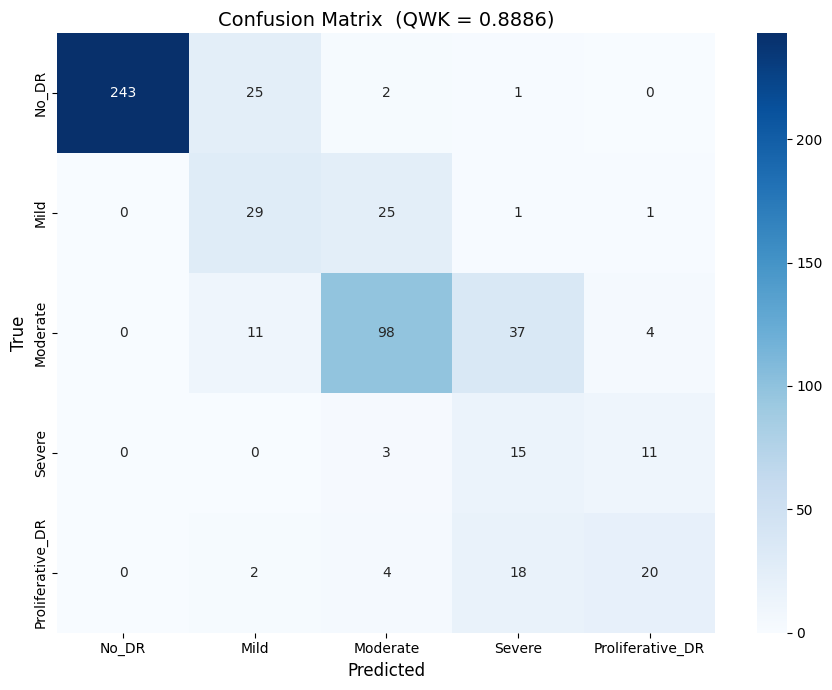

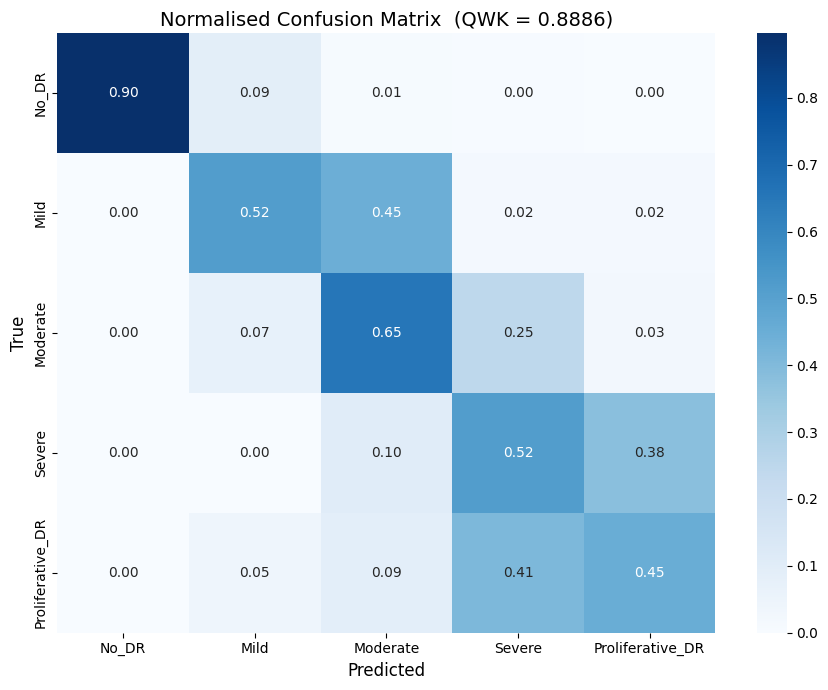

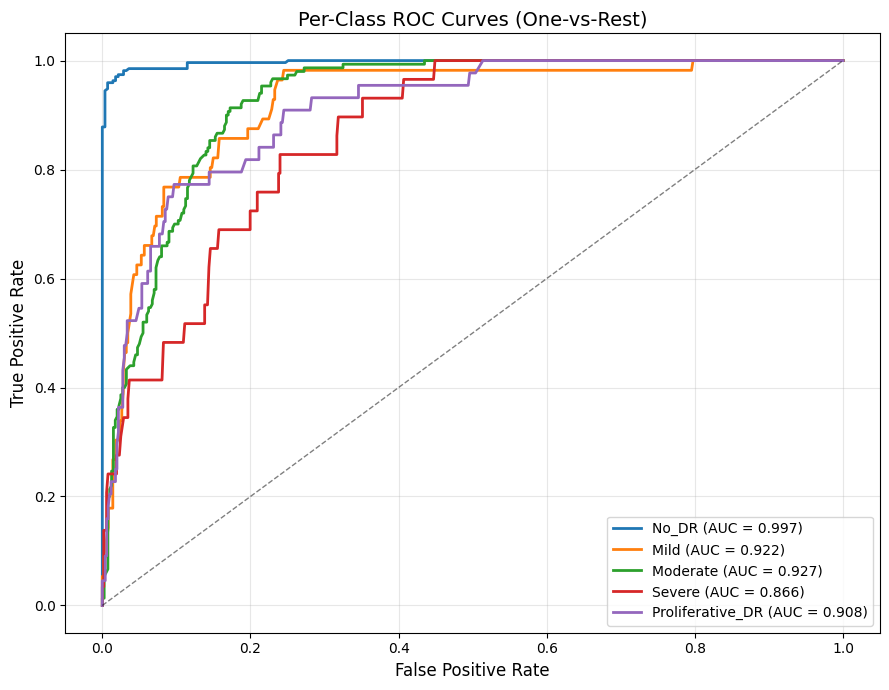

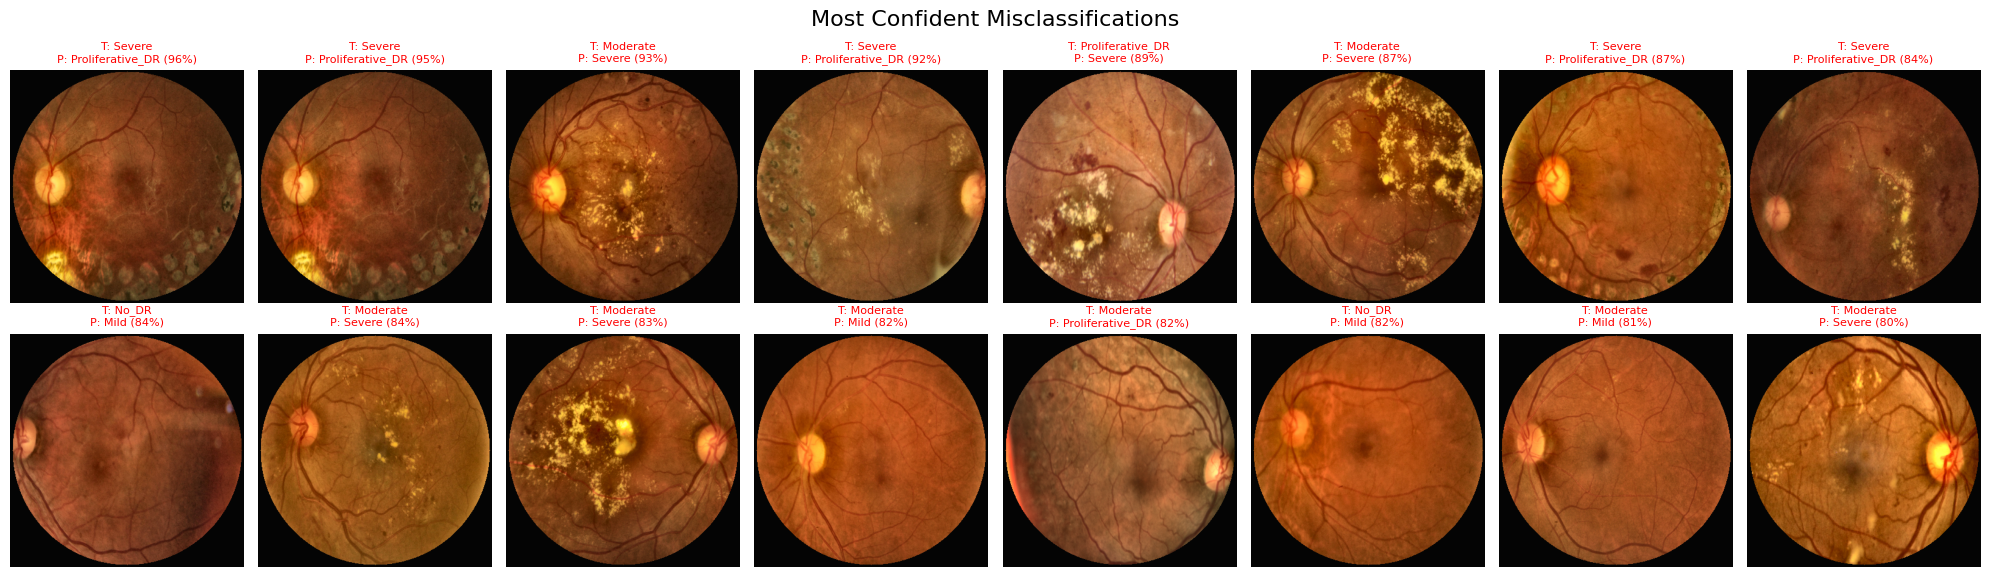

In [6]:
metrics = full_evaluation(
    model=model,
    test_loader=test_loader,
    device=device,
    test_dataset=test_dataset,
    valid_loader=valid_loader,
    save_dir=config.FIGURES_DIR,
)

write_run_manifest(
    config.RUN_MANIFEST_PATH,
    {
        "evaluation_notebook": {
            "qwk": float(metrics["qwk"]),
            "tta_used": bool(metrics.get("tta_used", False)),
            "qwk_argmax_no_tta": metrics.get("qwk_argmax_no_tta"),
            "figures_dir": config.FIGURES_DIR,
        }
    },
    merge=True,
)


## 2b. Optional: evaluation with TTA

`full_evaluation(..., use_tta=True)` runs **TTA** on validation and test, fits QWK thresholds on **val TTA** probabilities only, then applies them to **test TTA** probabilities (no test-label leakage). It is slower than §2; for a smoke test use e.g. `test_df.head(32)` and matching-sized `valid_df.head(32)`.


TTA transforms: 100%|██████████| 7/7 [00:08<00:00,  1.19s/it]


TTA eval: thresholds from TTA validation: [0.5259765625000001, 1.5404296874999996, 2.494140625, 3.4439453124999995]


Reference QWK (argmax, single-view test, no TTA): 0.8465
EVALUATION RESULTS

Quadratic Weighted Kappa : 0.8842
Accuracy                : 0.6927
Weighted ROC-AUC (OvR)  : 0.9552

                  precision    recall  f1-score   support

           No_DR     1.0000    0.8930    0.9435       271
            Mild     0.4419    0.6786    0.5352        56
        Moderate     0.7528    0.4467    0.5607       150
          Severe     0.1619    0.5862    0.2537        29
Proliferative_DR     0.6071    0.3864    0.4722        44

        accuracy                         0.6927       550
       macro avg     0.5927    0.5982    0.5531       550
    weighted avg     0.8001    0.6927    0.7234       550



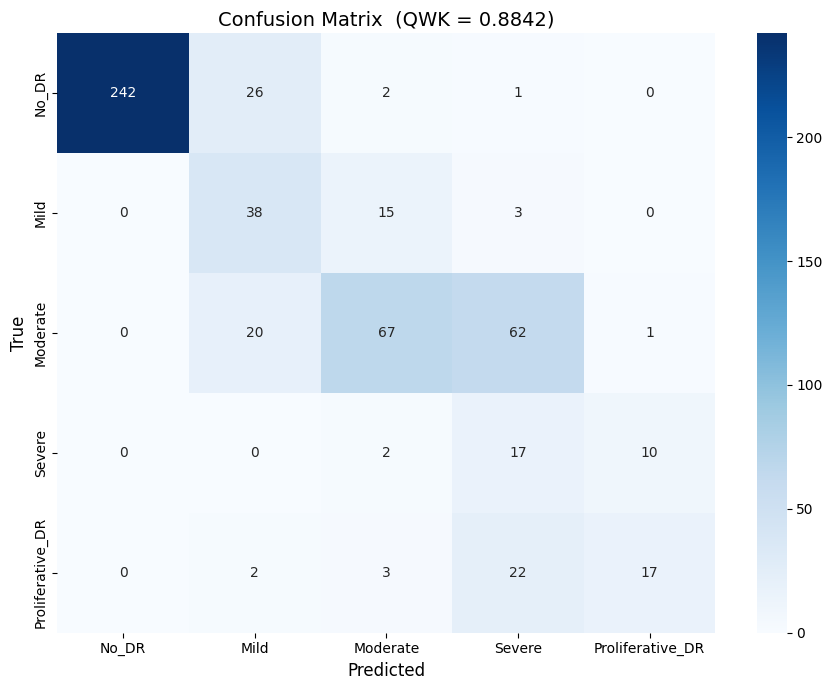

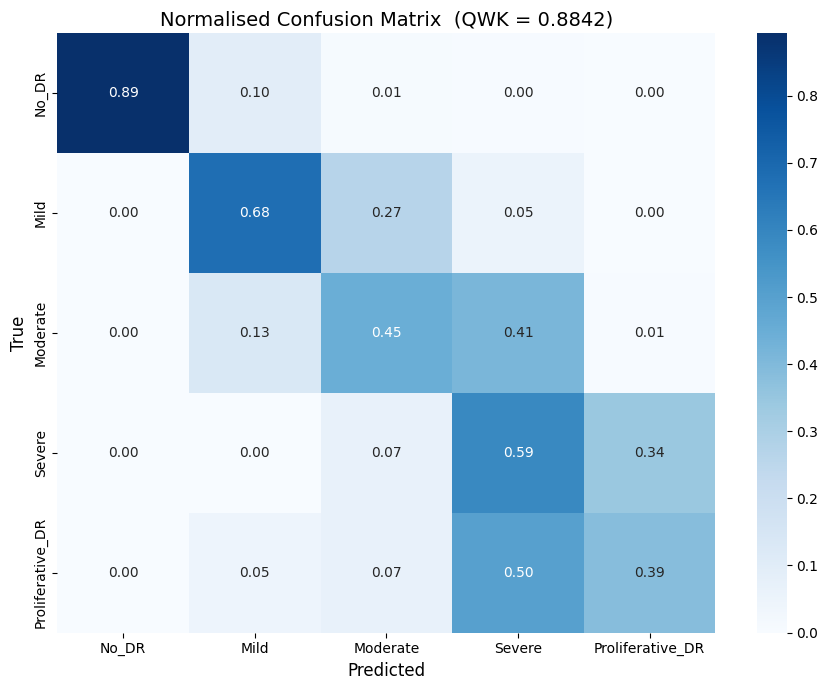

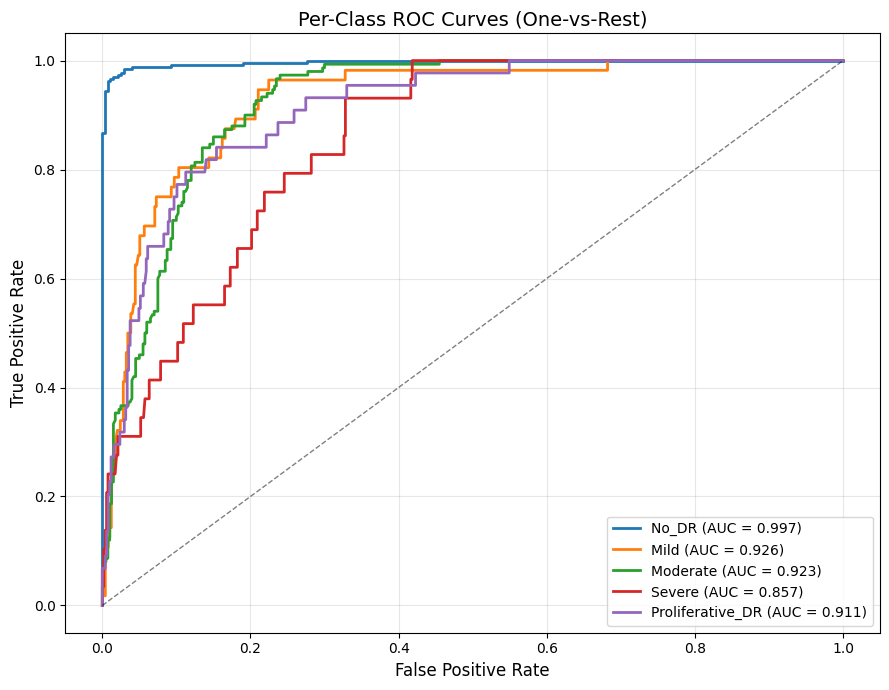

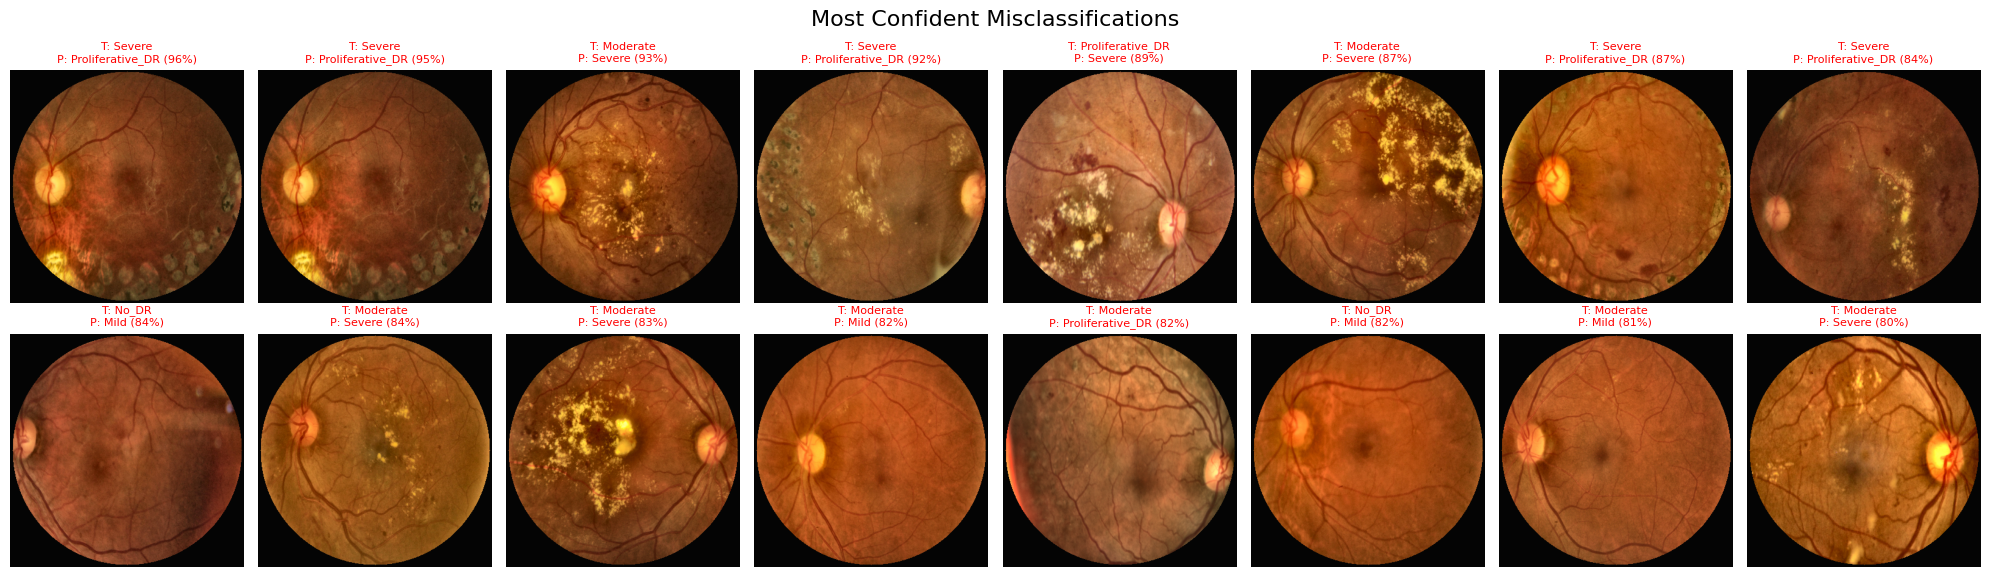

TTA QWK: 0.8842484086547752 | single-view argmax ref: 0.846522161553291


In [7]:
# Optional — uncomment to run TTA evaluation (slow on full splits)
metrics_tta = full_evaluation(
    model=model,
    test_loader=test_loader,
    device=device,
    test_dataset=test_dataset,
    use_tta=True,
    valid_df=valid_df,
    test_df=test_df,
    dataset_name="aptos",
)
print("TTA QWK:", metrics_tta["qwk"], "| single-view argmax ref:", metrics_tta.get("qwk_argmax_no_tta"))
write_run_manifest(
    config.RUN_MANIFEST_PATH,
    {"evaluation_notebook_tta": {"qwk": float(metrics_tta["qwk"]), "tta_used": True}},
    merge=True,
)


## 3. Training Curves


Loaded training history: stage2_history.json


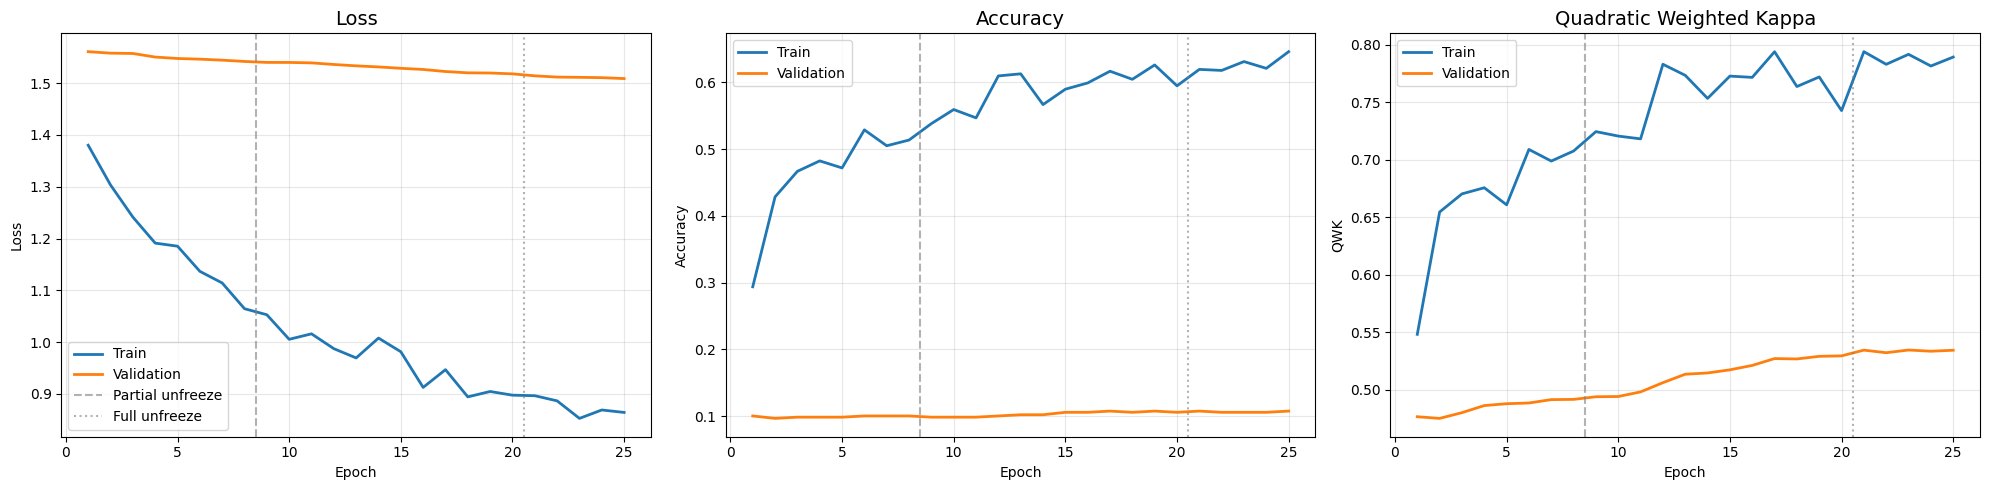

In [8]:
import json as json_mod

# Try Stage 2 history first, then Stage 1
for hist_name in ["stage2_history.json", "stage1_history.json", "training_history.json"]:
    history_path = os.path.join(config.LOGS_DIR, hist_name)
    if os.path.exists(history_path):
        with open(history_path) as f:
            history = json_mod.load(f)
        print(f"Loaded training history: {hist_name}")
        plot_training_curves(
            history,
            save_path=os.path.join(config.FIGURES_DIR, "training_curves.png"),
        )
        break
else:
    print("No training history found. Run training first.")


## 4. Single-Image Inference


In [9]:
from src.evaluate import predict_single_image


def find_image(images_dir, image_id):
    """Try common extensions and return the file path, or None."""
    for ext in (".jpeg", ".jpg", ".png", ".JPEG", ".JPG"):
        p = os.path.join(images_dir, image_id + ext)
        if os.path.isfile(p):
            return p
    return None


# Pick one image per class from the test set
CLASS_CODE = dict(enumerate(config.CLASS_NAMES))

print("Single-image predictions (one per class):\n")
for cls in sorted(test_df["level"].unique()):
    sample = test_df[test_df["level"] == cls].iloc[0]
    img_path = find_image(config.APTOS_IMAGES_DIR, sample["image"])
    if img_path is None:
        # Try preprocessed cache
        cache_dir = os.path.join(config.APTOS_DATA_DIR, f"preprocessed_{config.IMG_SIZE}_aptos")
        img_path = find_image(cache_dir, sample["image"])
    if img_path is None:
        print(f"  Class {cls} ({CLASS_CODE[cls]}): image not found")
        continue

    out = predict_single_image(model, img_path, device, show=False)
    true_name = CLASS_CODE[cls]
    pred_name = out["predicted_class"]
    pred_idx = config.CLASS_NAMES.index(pred_name)
    correct = "✅" if pred_idx == cls else "❌"
    print(
        f"  True: {true_name:20s} → Pred: {pred_name:20s} {correct}  (conf: {out['confidence']:.3f})"
    )


Single-image predictions (one per class):



  True: No_DR                → Pred: No_DR                ✅  (conf: 0.742)
  True: Mild                 → Pred: Mild                 ✅  (conf: 0.645)
  True: Moderate             → Pred: Moderate             ✅  (conf: 0.396)
  True: Severe               → Pred: Severe               ✅  (conf: 0.836)
  True: Proliferative_DR     → Pred: Proliferative_DR     ✅  (conf: 0.613)


## 5. Threshold Optimization

Standard argmax assigns to the highest-probability class. But ordinal class
boundaries can be improved by optimizing thresholds to maximize QWK.


In [10]:
from scipy.optimize import minimize
from sklearn.metrics import cohen_kappa_score

# Get predictions
y_true, y_pred, y_proba = predict(model, test_loader, device)

# Convert probabilities to continuous expected value
y_proba_np = y_proba.numpy() if isinstance(y_proba, torch.Tensor) else np.array(y_proba)
y_continuous = (y_proba_np * np.arange(5)).sum(axis=1)

# Optimize thresholds
def neg_qwk(thresholds):
    t = sorted(thresholds)
    preds = np.digitize(y_continuous, t)
    return -cohen_kappa_score(y_true, preds, weights="quadratic")

result = minimize(neg_qwk, [0.5, 1.5, 2.5, 3.5], method="Nelder-Mead")
opt_thresholds = sorted(result.x)
y_pred_opt = np.digitize(y_continuous, opt_thresholds)

qwk_argmax = cohen_kappa_score(y_true, y_pred, weights="quadratic")
qwk_opt = cohen_kappa_score(y_true, y_pred_opt, weights="quadratic")

print(f"Optimal thresholds: {[f'{t:.3f}' for t in opt_thresholds]}")
print(f"\nQWK (argmax):              {qwk_argmax:.4f}")
print(f"QWK (optimized thresholds): {qwk_opt:.4f}")
print(f"Improvement:                {qwk_opt - qwk_argmax:+.4f}")


Optimal thresholds: ['0.572', '1.198', '2.758', '3.421']

QWK (argmax):              0.8465
QWK (optimized thresholds): 0.8938
Improvement:                +0.0473


## 6. Test-Time Augmentation (TTA)

TTA averages predictions across multiple geometric transforms of the same image,
typically improving QWK by 0.5–2%.


In [11]:
# Standard prediction (no TTA)
y_true, y_pred_std, y_proba_std = predict(model, test_loader, device)
metrics_std = compute_metrics(y_true, y_pred_std, y_proba_std)

# TTA prediction (first 4 augmented views; full list has 7 — see get_tta_transforms)
y_true_tta, y_pred_tta, y_proba_tta = predict_with_tta(
    model, test_df, "aptos", device, batch_size=config.STAGE2_BATCH_SIZE, max_tta_views=4
)
metrics_tta = compute_metrics(y_true_tta, y_pred_tta, y_proba_tta)

print("Standard vs TTA comparison:")
print(f"  {'Metric':<20s} {'Standard':>10s} {'TTA (n=4)':>10s} {'Δ':>8s}")
print(f"  {'-'*50}")
for metric in ["qwk", "accuracy", "roc_auc_weighted"]:
    s = metrics_std[metric]
    t = metrics_tta[metric]
    print(f"  {metric:<20s} {s:>10.4f} {t:>10.4f} {t-s:>+8.4f}")


TTA transforms: 100%|██████████| 4/4 [00:04<00:00,  1.17s/it]

Standard vs TTA comparison:
  Metric                 Standard  TTA (n=4)        Δ
  --------------------------------------------------
  qwk                      0.8465     0.8497  +0.0032
  accuracy                 0.7182     0.7164  -0.0018
  roc_auc_weighted         0.9560     0.9557  -0.0004


## 7. Summary

Key metrics to report:
- **QWK** (Quadratic Weighted Kappa): the gold standard for DR grading
- **Per-class ROC-AUC**: how well each severity level is discriminated
- **Threshold-optimized QWK**: potential improvement with careful class boundaries
- **TTA QWK**: improvement from multi-view prediction averaging
- **Grad-CAM** (see notebook 05): visual explanations for clinical trust
